In [3]:
import numpy as np
import pandas as pd

In [4]:

match = pd.read_csv('matches.csv')
delivery = pd.read_csv('deliveries.csv')

print("Matches shape:", match.shape)
print("Deliveries shape:", delivery.shape)

Matches shape: (756, 18)
Deliveries shape: (179078, 21)


In [5]:
match.head()

,id,Season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,umpire3
0,1,IPL-2017,Hyderabad,05-04-2017,Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Sunrisers Hyderabad,35,0,Yuvraj Singh,"Rajiv Gandhi International Stadium, Uppal",AY Dandekar,NJ Llong,NaN
1,2,IPL-2017,Pune,06-04-2017,Mumbai Indians,Rising Pune Supergiant,Rising Pune Supergiant,field,normal,0,Rising Pune Supergiant,0,7,SPD Smith,Maharashtra Cricket Association Stadium,A Nand Kishore,S Ravi,NaN
2,3,IPL-2017,Rajkot,07-04-2017,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,field,normal,0,Kolkata Knight Riders,0,10,CA Lynn,Saurashtra Cricket Association Stadium,Nitin Menon,CK Nandan,NaN
3,4,IPL-2017,Indore,08-04-2017,Rising Pune Supergiant,Kings XI Punjab,Kings XI Punjab,field,normal,0,Kings XI Punjab,0,6,GJ Maxwell,Holkar Cricket Stadium,AK Chaudhary,C Shamshuddin,NaN
4,5,IPL-2017,Bangalore,08-04-2017,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,bat,normal,0,Royal Challengers Bangalore,15,0,KM Jadhav,M Chinnaswamy Stadium,NaN,NaN,NaN


In [6]:
match.shape

(756, 18)

In [7]:
delivery.head()

,match_id,inning,batting_team,bowling_team,over,ball,batsman,non_striker,bowler,is_super_over,...,bye_runs,legbye_runs,noball_runs,penalty_runs,batsman_runs,extra_runs,total_runs,player_dismissed,dismissal_kind,fielder
0,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,1,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
1,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,2,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
2,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,3,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,4,0,4,NaN,NaN,NaN
3,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,4,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
4,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,5,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,2,2,NaN,NaN,NaN


In [8]:
total_score_df = delivery.groupby(['match_id','inning']).sum()['total_runs'].reset_index()

In [9]:
total_score_df = total_score_df[total_score_df['inning'] == 1]

In [10]:
total_score_df

,match_id,inning,total_runs
0,1,1,207
2,2,1,184
4,3,1,183
6,4,1,163
8,5,1,157
...,...,...,...
1518,11347,1,143
1520,11412,1,136
1522,11413,1,171
1524,11414,1,155


In [11]:
match_df = match.merge(total_score_df[['match_id','total_runs']],left_on='id',right_on='match_id')

In [12]:
match_df

,id,Season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,umpire3,match_id,total_runs
0,1,IPL-2017,Hyderabad,05-04-2017,Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Sunrisers Hyderabad,35,0,Yuvraj Singh,"Rajiv Gandhi International Stadium, Uppal",AY Dandekar,NJ Llong,NaN,1,207
1,2,IPL-2017,Pune,06-04-2017,Mumbai Indians,Rising Pune Supergiant,Rising Pune Supergiant,field,normal,0,Rising Pune Supergiant,0,7,SPD Smith,Maharashtra Cricket Association Stadium,A Nand Kishore,S Ravi,NaN,2,184
2,3,IPL-2017,Rajkot,07-04-2017,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,field,normal,0,Kolkata Knight Riders,0,10,CA Lynn,Saurashtra Cricket Association Stadium,Nitin Menon,CK Nandan,NaN,3,183
3,4,IPL-2017,Indore,08-04-2017,Rising Pune Supergiant,Kings XI Punjab,Kings XI Punjab,field,normal,0,Kings XI Punjab,0,6,GJ Maxwell,Holkar Cricket Stadium,AK Chaudhary,C Shamshuddin,NaN,4,163
4,5,IPL-2017,Bangalore,08-04-2017,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,bat,normal,0,Royal Challengers Bangalore,15,0,KM Jadhav,M Chinnaswamy Stadium,NaN,NaN,NaN,5,157
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
751,11347,IPL-2019,Mumbai,05-05-2019,Kolkata Knight Riders,Mumbai Indians,Mumbai Indians,field,normal,0,Mumbai Indians,0,9,HH Pandya,Wankhede Stadium,Nanda Kishore,O Nandan,S Ravi,11347,143
752,11412,IPL-2019,Chennai,07-05-2019,Chennai Super Kings,Mumbai Indians,Chennai Super Kings,bat,normal,0,Mumbai Indians,0,6,AS Yadav,M. A. Chidambaram Stadium,Nigel Llong,Nitin Menon,Ian Gould,11412,136
753,11413,IPL-2019,Visakhapatnam,08-05-2019,Sunrisers Hyderabad,Delhi Capitals,Delhi Capitals,field,normal,0,Delhi Capitals,0,2,RR Pant,ACA-VDCA Stadium,NaN,NaN,NaN,11413,171
754,11414,IPL-2019,Visakhapatnam,10-05-2019,Delhi Capitals,Chennai Super Kings,Chennai Super Kings,field,normal,0,Chennai Super Kings,0,6,F du Plessis,ACA-VDCA Stadium,Sundaram Ravi,Bruce Oxenford,Chettithody Shamshuddin,11414,155


In [13]:
match_df['team1'].unique()

<StringArray>
[        'Sunrisers Hyderabad',              'Mumbai Indians',
               'Gujarat Lions',      'Rising Pune Supergiant',
 'Royal Challengers Bangalore',       'Kolkata Knight Riders',
            'Delhi Daredevils',             'Kings XI Punjab',
         'Chennai Super Kings',            'Rajasthan Royals',
             'Deccan Chargers',        'Kochi Tuskers Kerala',
               'Pune Warriors',     'Rising Pune Supergiants',
              'Delhi Capitals']
Length: 15, dtype: str

In [14]:
teams = [
    'Sunrisers Hyderabad',
    'Mumbai Indians',
    'Royal Challengers Bangalore',
    'Kolkata Knight Riders',
    'Punjab Kings',
    'Chennai Super Kings',
    'Rajasthan Royals',
    'Delhi Capitals'
]

In [15]:
match_df['team1'] = match_df['team1'].str.replace('Delhi Daredevils','Delhi Capitals')
match_df['team2'] = match_df['team2'].str.replace('Delhi Daredevils','Delhi Capitals')

match_df['team1'] = match_df['team1'].str.replace('Deccan Chargers','Sunrisers Hyderabad')
match_df['team2'] = match_df['team2'].str.replace('Deccan Chargers','Sunrisers Hyderabad')
match_df['team1'] = match_df['team1'].str.replace('Kings XI Punjab', 'Punjab Kings')
match_df['team2'] = match_df['team2'].str.replace('Kings XI Punjab', 'Punjab Kings')

In [16]:
match_df = match_df[match_df['team1'].isin(teams)]
match_df = match_df[match_df['team2'].isin(teams)]

In [17]:
match_df.shape

(641, 20)

In [18]:
match_df = match_df[match_df['dl_applied'] == 0]

In [19]:
match_df = match_df[['match_id','city','winner','total_runs']]

In [20]:
delivery_df = match_df.merge(delivery,on='match_id')

In [21]:
delivery_df = delivery_df[delivery_df['inning'] == 2]

In [22]:
delivery_df

,match_id,city,winner,total_runs_x,inning,batting_team,bowling_team,over,ball,batsman,...,bye_runs,legbye_runs,noball_runs,penalty_runs,batsman_runs,extra_runs,total_runs_y,player_dismissed,dismissal_kind,fielder
125,1,Hyderabad,Sunrisers Hyderabad,207,2,Royal Challengers Bangalore,Sunrisers Hyderabad,1,1,CH Gayle,...,0,0,0,0,1,0,1,NaN,NaN,NaN
126,1,Hyderabad,Sunrisers Hyderabad,207,2,Royal Challengers Bangalore,Sunrisers Hyderabad,1,2,Mandeep Singh,...,0,0,0,0,0,0,0,NaN,NaN,NaN
127,1,Hyderabad,Sunrisers Hyderabad,207,2,Royal Challengers Bangalore,Sunrisers Hyderabad,1,3,Mandeep Singh,...,0,0,0,0,0,0,0,NaN,NaN,NaN
128,1,Hyderabad,Sunrisers Hyderabad,207,2,Royal Challengers Bangalore,Sunrisers Hyderabad,1,4,Mandeep Singh,...,0,0,0,0,2,0,2,NaN,NaN,NaN
129,1,Hyderabad,Sunrisers Hyderabad,207,2,Royal Challengers Bangalore,Sunrisers Hyderabad,1,5,Mandeep Singh,...,0,0,0,0,4,0,4,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149573,11415,Hyderabad,Mumbai Indians,152,2,Chennai Super Kings,Mumbai Indians,20,2,RA Jadeja,...,0,0,0,0,1,0,1,NaN,NaN,NaN
149574,11415,Hyderabad,Mumbai Indians,152,2,Chennai Super Kings,Mumbai Indians,20,3,SR Watson,...,0,0,0,0,2,0,2,NaN,NaN,NaN
149575,11415,Hyderabad,Mumbai Indians,152,2,Chennai Super Kings,Mumbai Indians,20,4,SR Watson,...,0,0,0,0,1,0,1,SR Watson,run out,KH Pandya
149576,11415,Hyderabad,Mumbai Indians,152,2,Chennai Super Kings,Mumbai Indians,20,5,SN Thakur,...,0,0,0,0,2,0,2,NaN,NaN,NaN


In [23]:
delivery_df['total_runs_y'] = pd.to_numeric(
    delivery_df['total_runs_y'],
    errors='coerce'
)

# Calculate cumulative score for each match
delivery_df['current_score'] = (
    delivery_df.groupby('match_id')['total_runs_y']
    .cumsum()
)

In [24]:
delivery_df['runs_left'] = delivery_df['total_runs_x'] - delivery_df['current_score']

In [25]:
delivery_df['balls_left'] = 126 - (delivery_df['over']*6 + delivery_df['ball'])

In [26]:
delivery_df

,match_id,city,winner,total_runs_x,inning,batting_team,bowling_team,over,ball,batsman,...,penalty_runs,batsman_runs,extra_runs,total_runs_y,player_dismissed,dismissal_kind,fielder,current_score,runs_left,balls_left
125,1,Hyderabad,Sunrisers Hyderabad,207,2,Royal Challengers Bangalore,Sunrisers Hyderabad,1,1,CH Gayle,...,0,1,0,1,NaN,NaN,NaN,1,206,119
126,1,Hyderabad,Sunrisers Hyderabad,207,2,Royal Challengers Bangalore,Sunrisers Hyderabad,1,2,Mandeep Singh,...,0,0,0,0,NaN,NaN,NaN,1,206,118
127,1,Hyderabad,Sunrisers Hyderabad,207,2,Royal Challengers Bangalore,Sunrisers Hyderabad,1,3,Mandeep Singh,...,0,0,0,0,NaN,NaN,NaN,1,206,117
128,1,Hyderabad,Sunrisers Hyderabad,207,2,Royal Challengers Bangalore,Sunrisers Hyderabad,1,4,Mandeep Singh,...,0,2,0,2,NaN,NaN,NaN,3,204,116
129,1,Hyderabad,Sunrisers Hyderabad,207,2,Royal Challengers Bangalore,Sunrisers Hyderabad,1,5,Mandeep Singh,...,0,4,0,4,NaN,NaN,NaN,7,200,115
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149573,11415,Hyderabad,Mumbai Indians,152,2,Chennai Super Kings,Mumbai Indians,20,2,RA Jadeja,...,0,1,0,1,NaN,NaN,NaN,152,0,4
149574,11415,Hyderabad,Mumbai Indians,152,2,Chennai Super Kings,Mumbai Indians,20,3,SR Watson,...,0,2,0,2,NaN,NaN,NaN,154,-2,3
149575,11415,Hyderabad,Mumbai Indians,152,2,Chennai Super Kings,Mumbai Indians,20,4,SR Watson,...,0,1,0,1,SR Watson,run out,KH Pandya,155,-3,2
149576,11415,Hyderabad,Mumbai Indians,152,2,Chennai Super Kings,Mumbai Indians,20,5,SN Thakur,...,0,2,0,2,NaN,NaN,NaN,157,-5,1


In [27]:
#Binary Encoding
delivery_df['player_dismissed'] = delivery_df['player_dismissed'].fillna("0")

delivery_df['player_dismissed'] = delivery_df['player_dismissed'].apply(
    lambda x: x if x == "0" else "1"
)

delivery_df['player_dismissed'] = delivery_df['player_dismissed'].astype('int')

wickets = delivery_df.groupby('match_id')['player_dismissed'].cumsum().values

delivery_df['wickets'] = 10 - wickets

delivery_df.head()

,match_id,city,winner,total_runs_x,inning,batting_team,bowling_team,over,ball,batsman,...,batsman_runs,extra_runs,total_runs_y,player_dismissed,dismissal_kind,fielder,current_score,runs_left,balls_left,wickets
125,1,Hyderabad,Sunrisers Hyderabad,207,2,Royal Challengers Bangalore,Sunrisers Hyderabad,1,1,CH Gayle,...,1,0,1,0,NaN,NaN,1,206,119,10
126,1,Hyderabad,Sunrisers Hyderabad,207,2,Royal Challengers Bangalore,Sunrisers Hyderabad,1,2,Mandeep Singh,...,0,0,0,0,NaN,NaN,1,206,118,10
127,1,Hyderabad,Sunrisers Hyderabad,207,2,Royal Challengers Bangalore,Sunrisers Hyderabad,1,3,Mandeep Singh,...,0,0,0,0,NaN,NaN,1,206,117,10
128,1,Hyderabad,Sunrisers Hyderabad,207,2,Royal Challengers Bangalore,Sunrisers Hyderabad,1,4,Mandeep Singh,...,2,0,2,0,NaN,NaN,3,204,116,10
129,1,Hyderabad,Sunrisers Hyderabad,207,2,Royal Challengers Bangalore,Sunrisers Hyderabad,1,5,Mandeep Singh,...,4,0,4,0,NaN,NaN,7,200,115,10


In [28]:
delivery_df.head()

,match_id,city,winner,total_runs_x,inning,batting_team,bowling_team,over,ball,batsman,...,batsman_runs,extra_runs,total_runs_y,player_dismissed,dismissal_kind,fielder,current_score,runs_left,balls_left,wickets
125,1,Hyderabad,Sunrisers Hyderabad,207,2,Royal Challengers Bangalore,Sunrisers Hyderabad,1,1,CH Gayle,...,1,0,1,0,NaN,NaN,1,206,119,10
126,1,Hyderabad,Sunrisers Hyderabad,207,2,Royal Challengers Bangalore,Sunrisers Hyderabad,1,2,Mandeep Singh,...,0,0,0,0,NaN,NaN,1,206,118,10
127,1,Hyderabad,Sunrisers Hyderabad,207,2,Royal Challengers Bangalore,Sunrisers Hyderabad,1,3,Mandeep Singh,...,0,0,0,0,NaN,NaN,1,206,117,10
128,1,Hyderabad,Sunrisers Hyderabad,207,2,Royal Challengers Bangalore,Sunrisers Hyderabad,1,4,Mandeep Singh,...,2,0,2,0,NaN,NaN,3,204,116,10
129,1,Hyderabad,Sunrisers Hyderabad,207,2,Royal Challengers Bangalore,Sunrisers Hyderabad,1,5,Mandeep Singh,...,4,0,4,0,NaN,NaN,7,200,115,10


In [29]:
# crr = runs/overs
delivery_df['crr'] = (delivery_df['current_score']*6)/(120 - delivery_df['balls_left'])

In [30]:
delivery_df['rrr'] = (delivery_df['runs_left']*6)/delivery_df['balls_left']

In [31]:
def result(row):
    return 1 if row['batting_team'] == row['winner'] else 0

In [32]:
delivery_df['result'] = delivery_df.apply(result,axis=1)

In [33]:
final_df = delivery_df[['batting_team','bowling_team','city','runs_left','balls_left','wickets','total_runs_x','crr','rrr','result']]

In [34]:
final_df = final_df.sample(final_df.shape[0])

In [35]:
final_df.sample()

,batting_team,bowling_team,city,runs_left,balls_left,wickets,total_runs_x,crr,rrr,result
36911,Delhi Daredevils,Deccan Chargers,Cuttack,39,23,6,171,8.164948,10.173913,0


In [36]:
final_df.dropna(inplace=True)

/var/folders/_n/czrqrcl141g8g17rf9rqy6tc0000gn/T/ipykernel_12731/2709626079.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  final_df.dropna(inplace=True)


In [37]:
final_df = final_df[final_df['balls_left'] != 0]

In [38]:
X = final_df.iloc[:,:-1]
y = final_df.iloc[:,-1]
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=1)

In [39]:
X_train

,batting_team,bowling_team,city,runs_left,balls_left,wickets,total_runs_x,crr,rrr
51030,Rajasthan Royals,Kings XI Punjab,Chandigarh,173,100,8,195,6.600000,10.380000
65686,Kolkata Knight Riders,Chennai Super Kings,Chennai,86,72,9,139,6.625000,7.166667
145885,Chennai Super Kings,Mumbai Indians,Chennai,89,48,4,159,5.833333,11.125000
80701,Kolkata Knight Riders,Rajasthan Royals,Kolkata,57,66,8,132,8.333333,5.181818
19471,Chennai Super Kings,Deccan Chargers,Hyderabad,91,73,9,147,7.148936,7.479452
...,...,...,...,...,...,...,...,...,...
74948,Chennai Super Kings,Royal Challengers Bangalore,Chennai,40,19,6,165,7.425743,12.631579
77587,Chennai Super Kings,Rajasthan Royals,Chennai,39,27,8,185,9.419355,8.666667
146374,Royal Challengers Bangalore,Delhi Capitals,Delhi,67,31,5,193,8.494382,12.967742
24010,Mumbai Indians,Kings XI Punjab,Durban,74,64,6,119,4.821429,6.937500


In [40]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

trf = ColumnTransformer([
    ('trf', OneHotEncoder(sparse_output=False, drop='first'),
     ['batting_team', 'bowling_team', 'city'])
], remainder='passthrough')

In [41]:
# Compare multiple classification models and select the best one
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
import numpy as np

categorical_features = ['batting_team', 'bowling_team', 'city']

def make_preprocessor():
    return ColumnTransformer([
        ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False, drop='first'),
         categorical_features)
    ], remainder='passthrough')

models = {
    'Logistic Regression': LogisticRegression(solver='liblinear', max_iter=1000, random_state=1),
    'Decision Tree': DecisionTreeClassifier(max_depth=12, min_samples_leaf=10, random_state=1),
    'Random Forest': RandomForestClassifier(n_estimators=250, min_samples_leaf=3, class_weight='balanced', random_state=1, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=3, random_state=1)
}


models['Voting Classifier'] = VotingClassifier(

    estimators=[

        ('lr', LogisticRegression(solver='liblinear', max_iter=1000, random_state=1)),

        ('rf', RandomForestClassifier(n_estimators=150, random_state=1, n_jobs=-1)),

        ('gb', GradientBoostingClassifier(n_estimators=100, random_state=1))

    ],

    voting='soft'

)

results = []
trained_models = {}

for model_name, estimator in models.items():
    model_pipe = Pipeline(steps=[
        ('preprocessor', make_preprocessor()),
        ('model', estimator)
    ])
    model_pipe.fit(X_train, y_train)
    predictions = model_pipe.predict(X_test)

    results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'Recall': recall_score(y_test, predictions, zero_division=0),
        'F1 Score': f1_score(y_test, predictions, zero_division=0),
    })
    trained_models[model_name] = model_pipe

comparison_df = pd.DataFrame(results).sort_values(
    'F1 Score', ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))

# Select the model with the highest F1 score
best_model_name = comparison_df.loc[0, 'Model']
pipe = trained_models[best_model_name]  # Keep the name 'pipe' so the later notebook cells still work

print(f"Best model: {best_model_name}")
print(f"Best F1 Score: {comparison_df.loc[0, 'F1 Score']:.4f}")

,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.9971,0.9971,0.9973,0.9972
1,Voting Classifier,0.9501,0.9389,0.9678,0.9531
2,Decision Tree,0.8951,0.8973,0.9030,0.9002
3,Gradient Boosting,0.8272,0.8294,0.8436,0.8364
4,Logistic Regression,0.8029,0.8071,0.8193,0.8132


Best model: Random Forest
Best F1 Score: 0.9972


In [56]:
# LSTM Model for IPL Prediction

import time
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras import Model, Input
from tensorflow.keras.layers import LSTM, Dense, Dropout, Concatenate
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

tf.keras.utils.set_random_seed(42)

# 1. Prepare features
SEQ_LEN = 10
num_cols = ['runs_left', 'balls_left', 'wickets', 'total_runs_x', 'crr', 'rrr']
cat_cols = ['batting_team', 'bowling_team', 'city']

data = final_df.sort_index()
match_ids = delivery_df.loc[data.index, 'match_id']
pos = match_ids.groupby(match_ids, sort=False).cumcount().values

scaler = StandardScaler().fit(X_train[num_cols].replace([np.inf, -np.inf], 0))
values = scaler.transform(data[num_cols].replace([np.inf, -np.inf], 0)).astype('float32')

rows = np.arange(len(data))
seq = values[np.stack([rows - np.minimum(9-i, pos) for i in range(10)], axis=1)]
row_map = pd.Series(rows, index=data.index)

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(X_train[cat_cols])

def prepare(X):
    idx = row_map.loc[X.index].values
    return seq[idx], encoder.transform(X[cat_cols]).astype('float32')

X_train_seq, X_train_cat = prepare(X_train)
X_test_seq, X_test_cat = prepare(X_test)
y_train = np.asarray(y_train).ravel()
y_test = np.asarray(y_test).ravel()

# 2. Balance classes
classes = np.unique(y_train)
weights = compute_class_weight('balanced', classes=classes, y=y_train)
class_weights = dict(zip(classes, weights))

# 3. Build model
sequence_input = Input(shape=(SEQ_LEN, len(num_cols)))
team_input = Input(shape=(X_train_cat.shape[1],))

x = LSTM(64)(sequence_input)
team = Dense(32, activation='relu')(team_input)
x = Dropout(0.2)(Dense(32, activation='relu')(Concatenate()([x, team])))
output = Dense(1, activation='sigmoid')(x)

model = Model([sequence_input, team_input], output)
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# 4. Train
start = time.time()
model.fit(
    [X_train_seq, X_train_cat], y_train,
    epochs=12, batch_size=512, validation_split=0.1,
    callbacks=[EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)],
    class_weight=class_weights, verbose=1
)
print(f"Training time: {(time.time()-start)/60:.2f} minutes")

# 5. Evaluate
prob = model.predict([X_test_seq, X_test_cat], batch_size=1024, verbose=0).ravel()
pred = (prob >= 0.5).astype(int)

results = {'Model': 'LSTM',
           'Accuracy': accuracy_score(y_test, pred),
           'Precision': precision_score(y_test, pred, zero_division=0),
           'Recall': recall_score(y_test, pred, zero_division=0),
           'F1 Score': f1_score(y_test, pred, zero_division=0)}

display(pd.DataFrame([results]).round(4))

# 6. Compare models
comparison = pd.concat([comparison_df, pd.DataFrame([results])],
                       ignore_index=True).sort_values('F1 Score', ascending=False)
display(comparison.round(4))

Epoch 1/12
101/101 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.7578 - loss: 0.4856 - val_accuracy: 0.7934 - val_loss: 0.4169
Epoch 2/12
101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8203 - loss: 0.3816 - val_accuracy: 0.8406 - val_loss: 0.3465
Epoch 3/12
101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8620 - loss: 0.3160 - val_accuracy: 0.8819 - val_loss: 0.2777
Epoch 4/12
101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8967 - loss: 0.2560 - val_accuracy: 0.9129 - val_loss: 0.2189
Epoch 5/12
101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9175 - loss: 0.2105 - val_accuracy: 0.9333 - val_loss: 0.1781
Epoch 6/12
101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9296 - loss: 0.1783 - val_accuracy: 0.9420 - val_loss: 0.1522
Epoch 7/12
101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9367 - loss: 0.1587 - val_accuracy: 0.9469 - val_loss: 0.1357
Epoch 8/12
101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9431 - loss: 0.1429 - val_accuracy: 0.

,Model,Accuracy,Precision,Recall,F1 Score
0,LSTM,0.9706,0.9715,0.9724,0.972


,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.9971,0.9971,0.9973,0.9972
5,LSTM,0.9706,0.9715,0.9724,0.9720
1,Voting Classifier,0.9501,0.9389,0.9678,0.9531
2,Decision Tree,0.8951,0.8973,0.9030,0.9002
3,Gradient Boosting,0.8272,0.8294,0.8436,0.8364
4,Logistic Regression,0.8029,0.8071,0.8193,0.8132


In [43]:
y_pred = pipe.predict(X_test)

In [44]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix
)

y_pred = pipe.predict(X_test)
y_prob = pipe.predict_proba(X_test)[:, 1]

print("Selected model:", best_model_name)
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 Score :", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Selected model: Random Forest
Accuracy : 0.9971
Precision: 0.9971
Recall   : 0.9973
F1 Score : 0.9972

Confusion Matrix:
[[6774   22]
 [  20 7453]]


In [45]:
pipe.predict_proba(X_test)[10]

array([9.99129199e-01, 8.70801102e-04])

In [46]:
def match_summary(row):
    print("Batting Team-" + row['batting_team'] + " | Bowling Team-" + row['bowling_team'] + " | Target- " + str(row['total_runs_x']))

In [47]:
def match_progression(x_df,match_id,pipe):
    match = x_df[x_df['match_id'] == match_id]
    match = match[(match['ball'] == 6)]
    temp_df = match[['batting_team','bowling_team','city','runs_left','balls_left','wickets','total_runs_x','crr','rrr']].dropna()
    temp_df = temp_df[temp_df['balls_left'] != 0]
    result = pipe.predict_proba(temp_df)
    temp_df['lose'] = np.round(result.T[0]*100,1)
    temp_df['win'] = np.round(result.T[1]*100,1)
    temp_df['end_of_over'] = range(1,temp_df.shape[0]+1)

    #Score in each over
    target = temp_df['total_runs_x'].values[0]
    runs = list(temp_df['runs_left'].values)
    #Create a shallow copy
    new_runs = runs[:]
    runs.insert(0,target)
    temp_df['runs_after_over'] = np.array(runs)[:-1] - np.array(new_runs)
    #Wickets in each over
    wickets = list(temp_df['wickets'].values)
    new_wickets = wickets[:]
    new_wickets.insert(0,10)
    wickets.append(0)
    w = np.array(wickets)
    nw = np.array(new_wickets)
    temp_df['wickets_in_over'] = (nw - w)[0:temp_df.shape[0]]

    print("Target-",target)
    temp_df = temp_df[['end_of_over','runs_after_over','wickets_in_over','lose','win']]
    return temp_df,target


In [48]:
temp_df,target = match_progression(delivery_df,74,pipe)
temp_df

Target- 178


,end_of_over,runs_after_over,wickets_in_over,lose,win
10459,1,4,0,91.9,8.1
10467,2,8,0,92.7,7.3
10473,3,1,0,88.2,11.8
10479,4,7,1,94.7,5.3
10485,5,12,0,92.1,7.9
10491,6,13,0,90.7,9.3
10497,7,9,0,88.3,11.7
10505,8,15,0,90.3,9.7
10511,9,7,0,89.6,10.4
10518,10,17,0,89.6,10.4


Text(0.5, 1.0, 'Target-178')

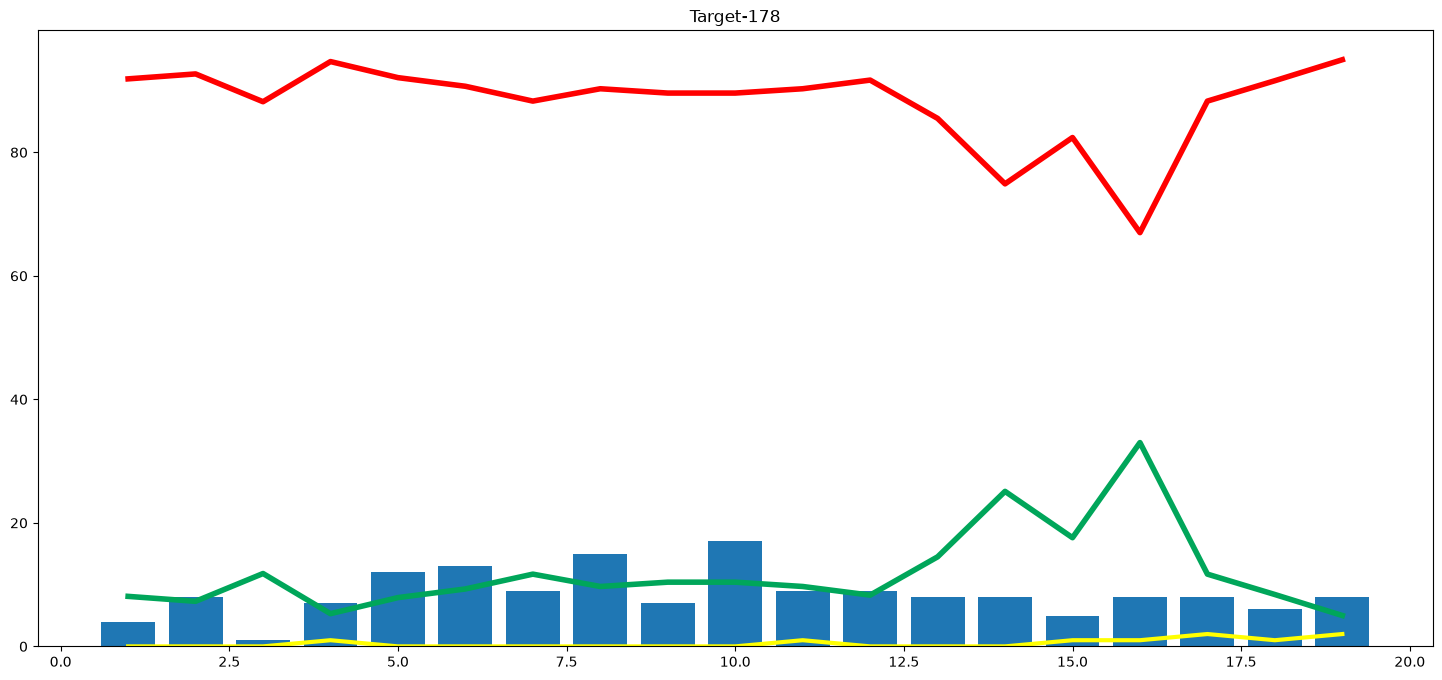

In [49]:
import matplotlib.pyplot as plt
plt.figure(figsize=(18,8))
plt.plot(temp_df['end_of_over'],temp_df['wickets_in_over'],color='yellow',linewidth=3)
plt.plot(temp_df['end_of_over'],temp_df['win'],color='#00a65a',linewidth=4)
plt.plot(temp_df['end_of_over'],temp_df['lose'],color='red',linewidth=4)
plt.bar(temp_df['end_of_over'],temp_df['runs_after_over'])
plt.title('Target-' + str(target))

In [50]:
teams

['Sunrisers Hyderabad',
 'Mumbai Indians',
 'Royal Challengers Bangalore',
 'Kolkata Knight Riders',
 'Punjab Kings',
 'Chennai Super Kings',
 'Rajasthan Royals',
 'Delhi Capitals']

In [51]:
delivery_df['city'].unique()

<StringArray>
[     'Hyderabad',      'Bangalore',         'Mumbai',         'Indore',
        'Kolkata',          'Delhi',     'Chandigarh',         'Jaipur',
        'Chennai',      'Cape Town', 'Port Elizabeth',         'Durban',
      'Centurion',    'East London',   'Johannesburg',      'Kimberley',
   'Bloemfontein',      'Ahmedabad',        'Cuttack',         'Nagpur',
     'Dharamsala',  'Visakhapatnam',           'Pune',         'Raipur',
         'Ranchi',      'Abu Dhabi',        'Sharjah',              nan,
         'Mohali',      'Bengaluru']
Length: 30, dtype: str

In [52]:
import pickle

# Save the selected best-performing model pipeline, including preprocessing
with open('pipe.pkl', 'wb') as file:
    pickle.dump(pipe, file)

print(f"Saved {best_model_name} pipeline to pipe.pkl")


Saved Random Forest pipeline to pipe.pkl
